In [1]:
import torch
import torch.optim.lr_scheduler as lr_scheduler
import torch.nn as nn
import re
import ordered_set
from itertools import combinations,pairwise
from typing import Dict,Sequence,Tuple,List
import random

In [2]:
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

In [4]:
device

device(type='cuda')

In [3]:
DATA_STRING="""
The morning light crept slowly across the valley, touching the tops of the old oak trees before it reached the quiet village below. Smoke rose from a few chimneys, and somewhere in the distance a dog barked twice and then fell silent. It was the kind of morning that made everything feel possible. Soon the village began to stir. Shutters opened, kettles whistled, and a baker's cart rattled over the cobblestones toward the square. Sunlight slid down the hillsides like poured honey, warming the slate roofs and waking the sleeping cats. By the time the church bell rang seven, the whole valley was fully, cheerfully awake.

Every good plan begins with a simple idea, and every simple idea needs time to grow. Some people rush ahead without looking back, while others study every detail before taking a single step. Neither approach is perfect, but a little patience and a little courage usually make a useful combination. Ideas are fragile at first, easily crushed by doubt or distraction. They need a notebook, a quiet hour, and a friend willing to ask honest questions. Once an idea survives its first few challenges, it starts to gather strength, and what seemed impossible on Monday begins to look surprisingly ordinary by Friday.

Along the river, the water moved with a steady rhythm that seemed to ignore the passing of the hours. Children skipped stones across the surface, counting the bounces aloud and arguing cheerfully about who had won. The afternoon stretched out lazily, warm and golden and full of small, unimportant joys. Further downstream, the current slowed and widened into a broad, glassy pool where dragonflies hovered above the reeds. A heron stood motionless at the edge, patient as a statue, watching for any flicker of silver. The children's voices faded behind the bend, and the river went on murmuring to itself, as it always had.

In the corner of the workshop stood a wooden table covered with tools, scraps of paper, and half-finished projects. Nobody else could have found anything on it, yet its owner could reach for exactly the right item without looking. Order, it turns out, is often a matter of personal definition. A row of hand planes hung on the wall, each with its own worn handle and slightly different blade. The owner claimed to remember which one belonged to which job, though every visitor suspected he simply trusted his fingers. Curled wood shavings gathered on the floor like pale ribbons, and the whole room smelled of pine and linseed oil.

A well-written sentence has a certain balance to it, like a bridge that carries the reader safely from one bank to the other. Too many words and the structure sags; too few and it collapses. The best writers spend hours removing what they wrote in minutes. Rhythm matters as much as meaning. A short sentence can land like a knock at the door, while a long one can wander through a landscape, gathering details before arriving at its point. Skilled writers learn to mix both, reading their drafts aloud until the music feels right and the clutter has quietly disappeared.

The old library smelled of dust, leather, and forgotten afternoons. Rows of shelves rose almost to the ceiling, each one crowded with volumes that had not been opened in decades. A single lamp glowed on the reading desk, waiting patiently for the next curious visitor to arrive. A narrow ladder on wheels slid along the highest shelves, squeaking gently whenever anyone climbed it. The librarian knew every volume by its spine and could describe the contents of half of them from memory. Visitors who asked for help were rarely sent away with only one book, and almost never left in a hurry.

Markets have always been places where people meet, trade, gossip, and quietly judge one another's purchases. The stalls fill with color in the early hours, and the air fills with the sounds of bargaining. By midday the best fruit is gone, and the rest of the day is spent in friendly conversation. Farmers arrived with crates of tomatoes, cheeses wrapped in cloth, and jars of honey glowing like amber in the light. Shoppers weaved between the tables, sniffing melons, squeezing peaches, and pretending not to be tempted by the pastry stall. Every purchase came with a bit of conversation, and every conversation came with a small discount.

Winter arrived earlier than anyone had expected, covering the fields with a thin layer of frost that glittered under the pale sun. The animals huddled closer together, and the farmers checked their supplies twice. Still, there was something comforting in the hush that settled over the countryside. Icicles hung from the barn roof like crystal teeth, dripping slowly whenever the sun broke through the clouds. Inside, the stove crackled, wool socks dried on a rack, and a pot of stew simmered from morning until night. Outside, the frozen fields lay quiet, resting beneath their white blanket until spring should call them back.

When the train finally pulled out of the station, the platform seemed suddenly larger and emptier than before. A few travelers waved until the last carriage disappeared around the bend. Then the clock ticked on, the pigeons returned, and the ordinary business of the day resumed. The station master folded his flag, straightened his cap, and returned to his little office, where a cold cup of tea awaited him. Somewhere down the line, the train carried its passengers toward new cities, new jobs, and new reunions. Back on the platform, a forgotten umbrella leaned against a bench, patiently waiting for its owner.

Curiosity is one of the most reliable engines of progress, powering everything from childhood questions to scientific revolutions. It asks why the sky is blue, how the clock works, and what lies beyond the next hill. Those who keep asking rarely run out of things to discover. Every great invention began with someone who could not leave a puzzle alone. They took things apart, asked awkward questions, and made a mess in the kitchen while trying to see how the world worked. Their friends found them exasperating, but history has been generous to the stubbornly curious, and far kinder to them than to the merely sensible.

The bakery on the corner opens before dawn, filling the street with the warm scent of fresh bread. Regular customers line up in silence, still half asleep, clutching coins and shopping bags. By the time the sun is fully up, the shelves are nearly bare and the baker is already thinking about tomorrow. Behind the counter, trays of golden rolls emerged from the oven in steaming, fragrant waves. The baker's hands, dusted with flour up to the elbows, moved with the ease of a lifetime's practice. Children pressed their noses against the glass display, choosing carefully between cinnamon twists, seeded loaves, and the mysterious pastry that always sold out first.

Mountains have a way of making human concerns seem pleasantly small. Standing at the summit, with the wind pulling at your jacket and clouds drifting far below, it is easy to forget the email you meant to answer. The view does not solve your problems, but it certainly changes their proportions. Far below, the valley lay stitched together by roads and rivers, tiny and neat like a model built by patient hands. A hawk drifted across the void without a single beat of its wings. Up here, the air was thin and cold and honest, and every breath seemed to carry a little more clarity than the last.

A good conversation moves like a walk through an unfamiliar town, with unexpected turns and surprising discoveries around each corner. Nobody quite knows where it will end, and that uncertainty is part of the pleasure. The best ones leave you feeling lighter than when you began. Some talks begin with the weather and end with the meaning of life, and nobody can remember how they got there. A shared laugh, a thoughtful silence, and a well-timed question can open doors that formal discussions never find. The teacups grow cold, the hours slip by, and both people leave feeling strangely lighter.

Somewhere between the first draft and the final version, the project changed shape entirely. What began as a modest experiment grew into something far more ambitious, with new features, new ideas, and new problems to solve. The team met the challenge with equal parts enthusiasm and exhaustion. Late nights blurred into early mornings, and the whiteboard filled with arrows, question marks, and increasingly cryptic notes. Someone brought pizza, someone else brought a brilliant solution, and someone forgot to save the file. Through it all, the team kept laughing, which turned out to be the most important ingredient of the entire project.

The lighthouse stood at the edge of the cliff, weathered by a hundred storms yet still faithfully turning its beam toward the sea. Ships passed in the night, their crews grateful for its presence, though few ever thought to thank the keeper. Reliable things are often invisible until they disappear. On stormy nights, the keeper climbed the spiral staircase with a flask of tea and a worn logbook, checking the lamp every hour. Waves hurled themselves against the rocks below, and the wind howled around the glass. By morning the storm would pass, the sea would calm, and no ship would ever know how close it had come.

Spring brought a sudden explosion of blossoms to the orchard, pink and white against a clear blue sky. Bees hummed from flower to flower, busy and indifferent to the admiring crowd below. It seemed as though the whole world had decided, all at once, to begin again. Petals drifted down in slow, pink flurries, settling on the grass, the benches, and the shoulders of anyone who lingered beneath the branches. Photographers crouched to catch the perfect angle, while grandparents sat in the sun and told stories of earlier springs. The orchard, briefly and gloriously, belonged to everyone.

Learning a new language is a little like moving into a house where all the furniture has been rearranged. At first you bump into everything and cannot find the simplest objects. Gradually, with practice and patience, the layout becomes familiar, and you begin to feel at home. Idioms are the trickiest furniture of all, because they never mean what they appear to say. Ordering coffee is easy; understanding a joke is a mountain. Yet each small victory, whether a correctly rolled sound or a properly guessed word, brings a rush of delight, and soon the once foreign sentences start to feel like your own.

The city never truly sleeps; it merely dims its lights and lowers its voice. Late-night cafés hum with quiet conversation, taxis glide through empty avenues, and somewhere a musician practices scales by an open window. Dawn arrives almost unnoticed, blending into the ongoing story of the streets. Delivery vans hummed through the pre-dawn streets, bakers switched on their ovens, and street sweepers traced slow lines along the curb. In the apartments above, a few windows glowed with the light of insomniacs, night-shift nurses, and people finishing letters they had been avoiding. The city breathed quietly, gathering strength for the morning rush.

Inside the small garden shed, rows of clay pots waited for the coming season. Seeds rested in labeled envelopes, and old gloves lay folded on the shelf beside a tin of twine. The gardener smiled at the sight, already imagining the tomatoes, beans, and sunflowers of summer. A dusty radio sat on the windowsill, tuned permanently to a station that played old songs. Spiders had claimed the upper corners, and a faded calendar still displayed a month from years ago. Yet the shed felt hopeful, a small cathedral of soil and string where every spring began with a plan and a packet of seeds.

Time behaves strangely on long journeys, stretching in the dull stretches and shrinking in the exciting ones. Hours pass in a blur of highway and horizon, then a single mountain pass takes an entire afternoon to cross. By the end, the trip feels both endless and far too short. Between towns, the landscape rolled by in long, hypnotic waves, broken only by the occasional gas station or roadside diner. Passengers dozed, read, or stared out at the endless fields, lost in the peculiar daydreams that travel encourages. When the destination finally appeared, it felt less like an arrival and more like a gentle awakening.

A tidy desk does not guarantee a tidy mind, but it certainly helps. Clearing away the clutter creates room for fresh thoughts, and a clean surface invites a clean start. Of course, by the end of the week the papers have usually crept back into their old positions. A single potted plant, a lamp, and a notebook can transform an ordinary desk into a place where thoughts feel welcome. The trick is knowing what to remove: the abandoned sticky notes, the tangle of cables, the coffee cup from three days ago. Once cleared, the surface seems to whisper, quite politely, that it is time to begin.

The orchestra tuned its instruments in a low, overlapping murmur that grew and faded like the sound of distant waves. Then the conductor raised his hands, and the hall fell silent. In that brief pause, before the first note, everyone in the room shared the same held breath. The first violin held a long, silver note, and the other instruments gathered around it, one by one, until the whole hall seemed to hum. Then the tuning ended, the lights dimmed, and a hush fell over the audience like a soft curtain. Somewhere in the back, someone stifled a cough, and the music began.

Bridges connect more than two banks of a river; they connect neighbors, markets, families, and stories. Long before engineers drew plans, people laid planks across streams and discovered that the far side was not so far after all. Every crossing is a small act of trust in a shared future. Some bridges are marvels of steel and cable, soaring across bays in graceful arcs. Others are humble wooden crossings, creaking underfoot as farmers lead their cows to the far pasture. Both serve the same quiet purpose, shortening distances that once seemed impossible and reminding us that separation is sometimes only a matter of engineering and goodwill.

Rainfall drummed steadily against the windows, turning the afternoon gray and the room warm by contrast. A pot of tea steamed on the table, and a half-read novel lay open beside it. There was nowhere else to be, and no reason to hurry. The gutters gurgled, the leaves dripped, and the street outside gleamed like polished glass. A neighbor hurried past under a crooked umbrella, splashing through puddles with mild despair. Indoors, the radiator ticked, the tea deepened in color, and the pages of the novel turned slowly, one after another, in the comfortable gray light.

Inventors rarely succeed on the first attempt, and the stories we tell about sudden breakthroughs tend to skip the years of frustration. Behind every clever device lies a drawer full of failed prototypes and a stubborn refusal to quit. Success is often just persistence wearing a better outfit. The workshop of a true inventor is a marvelous mess of springs, wires, magnets, and unlabeled jars. Sketches cover the walls, half of them abandoned, the other half wildly optimistic. Somewhere in the chaos, the next great idea is quietly assembling itself, waiting for a lucky combination of curiosity, coffee, and a broken toaster.

The fisherman rose before sunrise, as he had done every day for forty years, and walked down to the harbor with his nets slung over one shoulder. The boats bobbed gently in the half-light, ropes creaking. Out on the water, the day would offer either abundance or humility, and he accepted both. His boat, painted blue and white, had a name only he could pronounce properly, a word from his grandmother's dialect. He checked the engine, coiled the ropes, and pushed off from the dock without a word. Gulls followed him out to sea, hopeful and noisy, while the town behind him slowly began to wake.

Museums preserve the objects of the past, but they also preserve the questions that those objects raise. Who made this bowl, and what did they cook in it? Who wore this coat, and where were they going? Standing before a glass case, we join a conversation that began centuries ago. In a quiet gallery, a child stared at a suit of armor with wide, unblinking eyes, whispering questions to a patient parent. Nearby, an elderly visitor studied a faded map, tracing a route once traveled in youth. The museum guard leaned against the wall and smiled, knowing that this room belonged to everyone at once.

A small kindness can travel farther than its giver ever intends. A warm greeting in the morning lifts someone's mood, and that person, in turn, is gentler with a stranger later on. The ripples spread quietly, long after the original gesture is forgotten. It might be as simple as returning a lost glove or remembering a colleague's birthday. The recipient feels seen, the giver feels warm, and a tiny thread of connection is quietly woven into the day. Multiply such moments by thousands, and you have something that looks very much like a community.

By late afternoon, the market square had settled into a comfortable rhythm of slow footsteps and murmured negotiations. Vendors rearranged their remaining goods into hopeful pyramids, and cats prowled between the stalls in search of scraps. Nobody seemed in a rush, and the sun took its time setting. The fountain in the center gurgled contentedly, indifferent to the coins tossed into it by hopeful tourists. Old men played chess at a corner table, arguing softly over each move, while a group of teenagers shared a bag of roasted almonds. The square hummed with the low, easy music of everyday life.

The best maps are not just accurate but also inviting, tempting the reader to follow a thin line toward an unfamiliar name. Cartographers have always known this, decorating the edges with compass roses and imaginary creatures. Even now, a good map makes you want to pack a bag. A folded paper map, creased and coffee-stained, has a charm no screen can match. It shows not only where you are but also where you might go, offering roads you never noticed and villages you have never heard of. Spreading one across a table, you feel the first, delicious tug of an adventure not yet planned.

At the edge of the meadow, wildflowers swayed in the breeze like a slow, silent audience. Butterflies drifted between the blooms, and the grass whispered around the ankles of anyone who walked through. It was a place that asked nothing of you except to stay a while. A narrow footpath cut through the tall grass, leading toward a cluster of beehives painted white against the green. Somewhere a lark was singing, high and invisible, its notes tumbling down like scattered coins. Lying on your back among the flowers, you could watch clouds change shape and forget what day it was.

Teamwork is easy to praise and difficult to practice. It requires listening more than speaking, sharing credit more than claiming it, and admitting mistakes without excessive drama. When it works, however, the result is greater than any single person could have achieved alone. The best teams share an unspoken rhythm, passing tasks like a ball in a well-practiced game. They celebrate small wins, laugh at their own errors, and trust one another to catch what falls. When trouble arrives, as it always does, they face it together, and the trouble usually turns out smaller than expected.

The clock tower in the town center had been running five minutes fast for as long as anyone could remember. Locals simply adjusted, subtracting the difference in their heads without a second thought. Visitors, meanwhile, arrived late for everything and never quite understood why. The clockmaker had tried repairing it several times, but the townspeople objected. They liked their early clock, they said; it gave them five extra minutes of comfort each morning and a perfect excuse for arriving anywhere. Eventually the clockmaker gave up, and the tower kept ticking, cheerfully wrong, for decades.

Cooking is a form of quiet experimentation, a daily chemistry lesson disguised as dinner. A pinch of salt here, a splash of vinegar there, and the flavors shift in subtle and surprising ways. Even the mistakes are usually edible, which is more than most scientists can say. A wooden spoon, a heavy pot, and a handful of fresh herbs can accomplish more than any gadget. The kitchen fills with steam and aroma, and suddenly the whole house is paying attention. Even a simple soup, made with care, carries a quiet message: someone thought about you, and wanted you to be warm.

The desert at night is far from empty. Stars crowd the sky in dazzling numbers, and the cool air carries the faint rustle of small creatures beginning their evening rounds. Those who camp beneath such a sky rarely forget the silence, or the enormous sense of scale. By day, the sand burned under a merciless sun; by night, it cooled into silvery hills, sculpted by wind into elegant, changing curves. A fox trotted across the dunes, its ears alert, its footprints instantly erased. Around the campfire, travelers spoke in low voices, as though afraid to disturb the enormous quiet.

Every old house has its own personality, expressed in creaking stairs, stubborn doors, and windows that rattle in the wind. Its previous owners leave traces in the paint colors, the scratches on the floor, and the mysterious hooks in the ceiling. Living there feels like joining a long-running story. The attic held trunks full of letters, faded photographs, and dresses from forgotten decades. Each object seemed to hold its own small story, waiting for a listener. On rainy afternoons, the new owners climbed the narrow stairs with a flashlight and a mug of cocoa, gladly becoming historians of a family that was no longer theirs.

A sudden burst of laughter echoed from the kitchen, followed by the clatter of dishes and the sound of someone protesting innocence. The evening had been long and delightful, full of stories told twice and jokes that improved with repetition. Nobody wanted it to end. Someone had burned the toast, someone else had spilled the milk, and a third had begun narrating the disaster in the voice of a nature documentary. The whole family collapsed with laughter, wiping their eyes and clutching the counter. Years later, that ruined breakfast would be the story they told most often.

The scientist adjusted her instruments with careful, practiced hands, checking each reading against the last. Months of preparation had led to this single afternoon, and she knew that the results might be disappointing. Even so, she felt the familiar thrill of standing at the edge of the unknown. Around her, the laboratory hummed with fans, monitors, and the soft click of automated equipment. A half-finished sandwich sat forgotten on a shelf, and a whiteboard was crowded with equations and one large, underlined question mark. She took a deep breath, pressed a button, and watched the first numbers appear.

Gardens teach patience more effectively than any lecture. You plant a seed, water it faithfully, and then wait, trusting in processes you can neither see nor hurry. One morning a green shoot appears, and the whole effort suddenly feels worthwhile. Weeds, of course, have their own opinions on the matter and appear overnight in the most unwelcome places. Yet even weeding has its meditative charm, kneeling in the cool soil with the sun on your back. The gardener works, the birds comment, and the hours pass with unexpected gentleness.

Somewhere in the middle of the ocean, a small boat rocked gently on the swell, its sail a tiny white triangle against the vast blue. The sailor leaned back and watched the clouds, in no particular hurry to reach anywhere. Freedom, he thought, tastes a lot like salt. Dolphins appeared at the bow, leaping in easy arcs, as if to remind the sailor that he was merely a guest in their enormous home. He laughed aloud, alone and delighted, and adjusted the sail. Somewhere beyond the horizon lay land, but for now the sea was more than enough.

Good design is often invisible, the result of countless small decisions that make an object feel natural to use. The handle sits exactly where the hand expects it, and the button clicks with satisfying certainty. Only when something is poorly made do we notice the effort behind the ones done well. A well-designed chair invites you to sit before you have consciously decided to. A well-designed street guides your steps without a single sign. These quiet achievements come from designers who watch how real people behave, then build their work around those small, honest habits rather than around their own cleverness.

The festival began at dusk, with lanterns floating above the crowd and music drifting from every direction. Children ran between the food stalls, sticky with sugar, while their parents claimed benches and traded gossip. By midnight, the whole town seemed to glow. Fire dancers twirled in the town square, trailing bright ribbons of light, while a brass band played a lively march. Vendors sold grilled corn, sweet buns, and paper fans, and every doorway was strung with colored bulbs. For one night, the whole town forgot its worries and simply celebrated being together.

Memory is a curious storyteller, smoothing rough edges and rearranging events until they make a better tale. Two people can recall the same afternoon in completely different ways and both be entirely sincere. The truth probably lies somewhere in between, wearing a slightly different coat. A smell can bring back a whole summer; a song can reopen a forgotten room. Memories hide in unexpected places, waiting for the right key to turn. We carry them with us like a private library, constantly revised, occasionally misfiled, and always more precious than we realize.

Beneath the old stone arch, a street musician played a slow tune on a battered violin. Passersby slowed their steps without quite realizing it, drawn by the warm, wavering notes. A few coins clinked into the open case, and the melody carried on into the evening. Beneath the arch, the acoustics turned the violin into something larger, a warm, shimmering voice that seemed to belong to the stones themselves. A small dog sat at the musician's feet, listening with grave attention. When the tune ended, a few people clapped, and the dog, alone, seemed to bow in return.

The mountain path wound upward through pine forests and over narrow ridges, offering new views at every turn. Hikers paused often, partly to catch their breath and partly to admire the landscape. By the time they reached the summit, nobody could remember why they had complained about the climb. Wild thyme grew between the rocks, releasing its scent whenever a boot brushed against it. Streams tumbled down the slopes in silver threads, and marmots whistled warnings from the boulders. Every switchback revealed a wider view, and every rest stop tasted of cheese, bread, and well-earned satisfaction.

A blank page is both an invitation and a threat. It promises endless possibility yet demands that you begin somewhere, and the first words are always the hardest. Once the sentences start to flow, though, the fear usually fades, replaced by a quiet sense of momentum. Writers have invented countless rituals to defeat it: sharpening pencils, brewing tea, pacing the room, walking around the block. The truth is that the only cure is to write something, anything, and improve it later. A messy first draft is worth infinitely more than a perfect, imaginary one.

In the harbor town, gulls wheeled above the fish market, shrieking their opinions about the morning's catch. Crates of silver fish glittered on ice, and the smell of salt and diesel filled the air. It was loud, messy, and completely alive. Fishermen mended nets on the quay, their fingers moving with quiet expertise, while children dangled crab lines from the dock. A faded blue ferry sounded its horn and slid away toward the islands. The scent of frying fish drifted from a nearby café, and the whole harbor seemed to hum with contented industry.

The professor peered over his glasses at the restless class and began, as always, with a story rather than a definition. Within minutes the room had fallen quiet, everyone leaning forward to hear what came next. He had discovered long ago that curiosity is easier to awaken than to command. He told of a lost explorer, a stubborn mule, and a mathematical mystery that took a hundred years to solve. The students laughed, gasped, and scribbled furious notes, barely noticing that they were learning. When the bell rang, several stayed behind, hungry for the ending, and he gladly obliged.

Long shadows stretched across the football field as the players trudged home, muddy and triumphant. Someone hummed a half-remembered chant, and someone else carried the ball under one arm like a trophy. The game itself would soon be forgotten, but the friendship would last. They limped toward the bus, comparing bruises and rehashing every dramatic moment. The coach counted heads, handed out water bottles, and pretended not to smile. The score had been close, the mud deep, and the effort magnificent, and on the ride home the windows steamed up with singing.

Every traveler eventually learns that the best moments of a trip are rarely the ones on the itinerary. A wrong turn leads to a hidden courtyard, a missed bus leads to a long conversation with a stranger, and a rainy afternoon leads to the finest meal of the week. Plans are useful, but surprises are better. A tiny bakery discovered by accident, a sunset viewed from a stranger's terrace, a conversation in broken language that somehow says everything: these are the souvenirs that last. Photographs fade and postcards curl, but the memory of a small, unexpected joy remains vivid for years, quietly waiting to be retold.

The newspaper landed on the doorstep with a soft thud, and the smell of coffee drifted from the kitchen. It was an ordinary morning in an ordinary neighborhood, yet there was comfort in the routine. Small rituals hold the days together like stitches in a quilt. The neighbor's radio murmured the weather report, a jogger passed with steady steps, and the mail carrier whistled somewhere down the street. Nothing dramatic was happening, and that was precisely the charm. Ordinary mornings, repeated faithfully, form the quiet foundation on which extraordinary days are built.

Thunderclouds gathered slowly on the horizon, dark and heavy, while the air grew thick with anticipation. Birds fell silent, and the leaves turned their pale undersides upward. Then the first fat drops landed on the dusty road, and the whole world exhaled. Lightning flickered far off, silent at first, then followed by a low, rolling growl. The farmers hurried to gather their tools, and children were called inside. Within minutes, the storm arrived in full, rattling the windows and drumming the roofs, and afterward the whole countryside smelled clean and new.

An honest mistake is often the best teacher, provided we are willing to listen. It reveals the gap between what we believed and what is actually true, and it does so with unforgettable clarity. Those who fear errors too much miss the lessons hidden inside them. Nobody enjoys being wrong, yet nearly everyone can name a mistake that changed them for the better. The failed recipe that led to a new dish, the wrong turn that led to a lifelong friend, the bad grade that led to real study: these are the humble teachers of adult life.

The village well had stood in the same spot for centuries, its stones worn smooth by countless hands. Generations had gathered there to fetch water, exchange news, and settle small disputes. Though the pipes now ran into every house, some people still stopped by out of habit. The bucket, once made of oak, was now replaced with a plastic one, but the rope still smelled faintly of hemp. Old women told young women where the sweetest water could be found, and young women pretended to listen. The well listened, as wells always do, and kept every secret.

Across the frozen lake, skaters glided in wide, lazy circles, their breath rising in small white clouds. Laughter carried easily over the ice, and a vendor sold hot chestnuts from a cart near the shore. The cold was fierce, but nobody seemed to mind. A group of boys played hockey at the far end, their sticks clacking, their shouts echoing across the ice. Near the shore, a couple held hands, wobbling comically. The lake creaked and sang beneath them, an old, cold instrument tuned by the deep winter, and nobody found it frightening.

Words have weight, though we often use them carelessly. A single sentence can comfort a grieving friend, inspire a discouraged student, or wound someone deeply without our even noticing. Choosing them thoughtfully is one of the simplest and most powerful skills a person can develop. Consider how much a simple thank-you can accomplish, or an honest apology, or a well-timed compliment. Words are free, yet they carry the power to repair, encourage, and inspire. Spending them wisely, like coins in a small, precious purse, is one of the finest habits anyone can develop.

The workshop hummed with the steady sound of machinery, punctuated by the occasional clang of metal on metal. Sawdust hung in the sunlight like drifting gold, and the smell of fresh-cut timber filled the room. Here, ideas became objects, and objects became useful. Apprentices swept the floor, sharpened blades, and watched the masters closely, learning by imitation before they ever learned by theory. The clang of the hammer set the rhythm of the day, and pride filled the room whenever a finished piece was lifted from the bench. Skill, after all, is simply patience made visible.

A stray cat wandered into the courtyard one autumn evening and decided, with great dignity, to stay. It accepted food as a tribute rather than a gift and claimed the warmest windowsill as its right. Within a week, the entire household was working for it. It sat by the door each evening, blinking slowly, silently demanding tribute. Soon a bowl appeared, then a cushion, then a name, though the cat pretended not to recognize it. By winter, it slept on the sofa, purring loudly, entirely convinced that the house had been built expressly for its comfort.

Great cities are built on countless small routines: the tram arriving on time, the shopkeeper unlocking the door, the neighbor watering the plants on the balcony. None of these acts is remarkable alone, yet together they form the quiet machinery of daily life. We notice them mostly when they stop. Behind every lit window is someone making dinner, reading a story, or worrying about the rent. Together these small lives form the enormous, glittering creature we call a city. It grows, changes, and forgets itself daily, yet somehow remains recognizable, like a familiar face in a crowd.

The first snowfall of the year turned the familiar streets into a soft, unfamiliar landscape. Cars became rounded white shapes, and footprints appeared in fresh lines across the sidewalks. Even the noise of traffic seemed muffled, as though the city were listening. Children pressed their faces against the windows, begging to go outside, while parents sighed and searched for mittens. Within an hour, the park was full of snowmen, snow angels, and warm, breathless laughter. The magic of the first snow is that it makes everyone, for a moment, wonderfully young again.

Perseverance rarely looks heroic while it is happening. It looks like showing up on a rainy Tuesday, doing the same task for the hundredth time, and refusing to be discouraged by slow progress. Only later, in hindsight, does it appear like greatness. There are no trumpets when you finish the fiftieth practice session or the two-hundredth page. There is only a quiet sense of movement, like a slow river cutting stone. Those who keep going, despite the lack of applause, eventually discover that they have built something extraordinary out of ordinary days.

On the last day of summer, the beach was almost empty, and the sea seemed calmer than usual. A few families lingered by the water, reluctant to admit that the season was over. The lifeguard's chair stood unoccupied, watching the waves in silence. The umbrellas were being folded, the ice cream stand was shuttered, and a wistful wind carried the smell of seaweed across the sand. A child built one last castle, then watched the tide slowly claim it. Nobody said goodbye to the summer aloud, but everyone felt it slipping away.

An unexpected letter arrived in the mail, written in an unfamiliar hand and postmarked from a distant country. Curiosity won out over caution, and the envelope was open before the kettle had boiled. Inside, a few brief lines rearranged the entire afternoon. The paper was thin and slightly crumpled, covered with elegant handwriting in blue ink. It spoke of a family connection, a forgotten house, and an invitation to visit. The reader put down the kettle, sat at the kitchen table, and began to imagine an entirely different autumn.

Some of the finest ideas arrive in the least convenient moments: in the shower, on a crowded bus, or just as sleep begins to settle in. The mind, finally released from its tasks, wanders freely and stumbles upon a solution. Keeping a notebook nearby is the sensible response. Great thinkers have long noticed this odd pattern and built habits around it: long walks, warm baths, quiet mornings with nothing planned. The brain, it seems, does its best work when it feels least pressured. Give it space, and it often returns the favor with surprising gifts.

The orchard at harvest time was a scene of cheerful chaos, with ladders leaning against every tree and baskets overflowing with ripe fruit. Workers called to one another across the rows, and the sweet smell of apples hung in the warm air. Nothing else in the year felt quite so generous. By evening, the wagons were heaped with fruit, and the workers gathered under the trees to share bread, cheese, and cider. Someone brought out a guitar, and the songs went on until the stars appeared. It was hard work, but the reward was plainly visible, and sweetly edible.

In the quiet hours before an exam, a strange calm often descends. The notes have been reviewed as many times as possible, and the remaining questions cannot be answered by more worrying. All that is left is to breathe, trust the preparation, and walk into the room. Students sat in rows, pencils poised, listening to the soft rustle of paper and the ticking of the wall clock. Some closed their eyes for a moment, gathering their thoughts; others glanced nervously around. Then the first page was turned, and the quiet, focused work began.

The bus rattled along the coastal road, windows fogged with the breath of sleepy passengers. Outside, the sea shifted from gray to green as the clouds broke apart. Someone at the back began to hum, and slowly, quietly, others joined in. An elderly woman shared a bag of mints with the stranger beside her, and a teenager slept with his forehead against the glass. Each stop brought a new smell of salt, fish, or wet stone. The driver hummed along to the radio, unhurried, and the sea flashed by in glimpses of silver.

A skilled craftsman treats time differently from most people, measuring progress in careful strokes rather than hurried deadlines. Each joint must fit, each surface must be smooth, and each detail must be considered. The finished piece carries that patience within it, visible to anyone who looks closely. In his workshop, no clock hung on the wall, because time was measured by the state of the work. A chair took as long as a chair required, and a violin took considerably longer. Customers who complained about the wait were invited to watch, and most left as quiet, converted admirers.

The garden gate creaked open, and a small figure slipped through, clutching a jar and a magnifying glass. Today's mission was to find the biggest beetle in the yard, and nothing would stand in the way. The bushes rustled, and the great expedition began. Behind the shed, under a sagging leaf, sat the most magnificent beetle the small explorer had ever seen, glistening like a green jewel. She held her breath, lowered the jar carefully, and whispered a secret promise to release it after a proper introduction. It was, she decided, the best day of the year.

Rivers carve canyons not through force but through persistence, one drop and one grain of sand at a time. Given enough years, even the gentlest current can reshape a mountain. There is a lesson in that for anyone who feels their efforts are too small to matter. Standing on the canyon rim, watching the far-off silver thread of water, one feels the immensity of time in a new way. Each layer of rock records a chapter of an ancient story, written slowly and without hurry. The river, still working, has all the patience in the world.

Late in the evening, the streetlamps flickered on one by one, casting warm pools of light along the pavement. Moths gathered around them in loose, restless clouds, and the air smelled faintly of jasmine. It was a good hour for a slow walk and an unhurried thought. A couple strolled by arm in arm, deep in soft conversation, while a bicycle bell tinkled somewhere behind them. In the windows above, curtains glowed yellow and orange, hinting at dinners, games, and quiet family evenings. The night, for once, seemed to be on everybody's side.

The old radio crackled to life, filling the kitchen with a warm, slightly distorted melody. Grandmother hummed along without noticing, stirring a pot of soup with the ease of long experience. Some songs, once learned, never leave a person, and some kitchens always feel like home. The song ended, and a cheerful announcer read a list of birthday greetings and local news. Grandmother tasted the soup, added a pinch of salt, and nodded with satisfaction. Outside, the last light faded from the window, and the kitchen glowed like a small, warm lantern.

Innovation often comes from combining familiar things in unfamiliar ways. A wheel joins a suitcase, a camera joins a telephone, and suddenly everyday life looks slightly different. The raw materials were always there; someone simply had the imagination to put them together. Every era has its own quiet inventions that seem obvious afterward: the sticky note, the zipper, the paperclip. Their creators were not necessarily geniuses, only observant people who noticed a small frustration and refused to accept it. Progress, in this sense, is a kind of collective, cheerful stubbornness.

The village school consisted of a single room with a wood stove, a chalkboard, and two dozen mismatched desks. Yet within those walls, children learned to read, to count, and to argue politely. Great institutions do not always come with great buildings. In winter, the children took turns bringing firewood, and in summer they held lessons under the apple tree. The teacher knew every family by name and every child by temperament. When the school finally closed, generations of former students gathered to say thanks, standing in the empty room, remembering.

At the top of the hill, a lone tree stood against the sky, bent by generations of wind but still stubbornly green. Travelers used it as a landmark, and lovers carved their initials into its bark. It had witnessed more history than any book in the valley. Its roots gripped the stony soil like a fist, and its trunk twisted gracefully, shaped by centuries of storms. In autumn, its leaves turned a fierce, flaming gold, visible for miles. Shepherds rested in its shade, and every traveler who passed left it a small, silent word of gratitude.

A pause in the middle of a busy day can feel like a small vacation. Stepping outside for a few minutes, looking at the clouds, and letting the mind wander restores something that a full schedule tends to drain. It costs nothing, and it pays back handsomely. Some people take a short walk, others sip tea by the window, and still others simply close their eyes for sixty seconds. The method matters far less than the willingness to stop. When you return to the task, it often seems lighter, kinder, and a little more interesting than before.

The trail of footprints led across the dunes, softening and fading as the wind swept the sand smooth. Whoever had passed this way was long gone, leaving only a temporary signature on the landscape. The desert accepts visitors politely and keeps no records. Somewhere beyond the next ridge, a caravan of camels moved slowly toward a distant well, their bells jangling in the still air. The sun climbed, the sand shimmered, and the horizon trembled in the heat. In the desert, every journey is a lesson in humility and endurance.

Kindness in a large city often takes the form of small, unnoticed gestures: holding a door, offering a seat, pointing a lost tourist in the right direction. These moments rarely make headlines, yet they define the character of a place. A city is only as warm as the people who share it. A stranger helps a mother carry her stroller up the subway steps; a barista remembers a customer's name; a neighbor leaves soup outside a sick friend's door. None of them seek recognition. Together they make the difference between a city that merely functions and a city that feels, unmistakably, like home.

An unfinished painting rested on the easel, its colors bright and its edges still uncertain. The artist stepped back, squinted, and tilted her head as if listening for advice. Sometimes the hardest part of creating something is knowing when to stop. The colors on the palette had begun to dry, forming small hills of crimson, ochre, and blue. The window behind the easel let in a soft, north-facing light, perfect for painting. She wiped her brush, sat back, and decided that the canvas would tell her when it was finished.

The sound of distant church bells drifted across the fields, marking the hour in slow, solemn notes. Farmers paused in their work, wiped their brows, and glanced at the sun. It was nearly noon, and the shade of the old chestnut tree beckoned. Sparrows rose from the hedgerows in a startled cloud, then settled again, unbothered. In the distance, a tractor rumbled along a dusty lane, trailing a ribbon of pale smoke. It was a peaceful, ordinary noon, full of small sounds that formed a music older than any orchestra.

In a busy kitchen, timing is everything. The sauce must be ready when the pasta finishes, the bread must emerge just before the soup is served, and the dessert must wait patiently in the cold. A good cook conducts these details like a quiet, hungry orchestra. Chefs called out orders in quick, clipped voices, pans hissed, and a cascade of plates clattered onto the counter. Through the chaos, a calm sous-chef arranged a garnish with tweezers, delicate as a surgeon. Somehow, dish by dish, the evening's meal appeared, and the dining room never suspected a thing.

The astronaut floated near the window, watching the blue curve of Earth glide slowly past. From such a height, borders disappeared and cities became scattered clusters of light. The silence was profound, and so was the feeling of being small and lucky. On the ground, families watched her livestream and pointed at the tiny bright dot crossing the night sky. Onboard, she ate dinner from a pouch, laughed at a floating pen, and wrote a postcard she would deliver in person. Every sunrise, sixteen times a day, felt like a private gift.

Old friendships have their own language, made up of shared jokes, half-finished sentences, and comfortable pauses. Years may pass between visits, yet the conversation resumes as if it had never stopped. Few treasures in life are as reliable, or as underappreciated. They met in a crowded café, embraced awkwardly, and began talking as if they had never parted. The waiter refilled the coffee twice and finally stopped asking if they needed anything. Hours later, they promised to meet again soon, and both, remarkably, meant it.

A single candle burned in the window, small but steady against the gathering dark. Its light spilled onto the snow outside, painting a warm rectangle on the ground. Whoever was traveling that night would see it and know that a welcome awaited. In the kitchen, a pot of soup simmered on the stove, and the table was set for guests who might not come. Hospitality, the old woman believed, was not measured by the number of visitors but by the readiness of the welcome. Outside, the snow continued to fall, soft and patient.

The recipe had been passed down through four generations, written in faded ink on a stained and folded card. Every cook who inherited it added a small note in the margin, a tweak here, a warning there. The dish itself tasted like a family gathered around a table. The card had grown so fragile that it was now sealed in plastic and kept in a drawer, replaced by a photocopy on the kitchen shelf. Yet the original held the true magic: the smudges of butter, the shaky handwriting, the words "add more sugar" scribbled in three different inks.

Rush hour in the city is a strange kind of choreography, with thousands of strangers moving in intersecting lines without ever quite colliding. Each person is wrapped in private thoughts, headphones, and half-remembered tasks. Yet somehow the whole crowd flows, with astonishing efficiency, toward the evening. Trains arrived in gusts of warm air, doors sighed open, and the crowd flowed in and out like a slow, human tide. A man played a saxophone near the exit, ignored by most and appreciated by a few. Above ground, the sky turned orange, and the day's work was finally done.

The young violinist drew her bow across the strings, and a clear, trembling note filled the empty hall. Her teacher listened from the back row, arms folded, expression unreadable. Only when the final chord faded did he allow himself a small, satisfied nod. Her fingers trembled slightly on the strings, but the tone remained pure. She remembered her teacher's advice: breathe first, then play. The melody rose, wavered, and steadied, filling the hall with a fragile, luminous sound that made every listener sit a little straighter.

Forests keep their own quiet time, measured in seasons and growth rings rather than minutes. Beneath the canopy, fallen leaves become soil, seedlings reach toward scattered sunlight, and fungi trade nutrients through hidden networks. Standing among the trees, one senses a patient intelligence that needs no explanation. Woodpeckers tapped somewhere overhead, and a deer stepped silently between the ferns, pausing to sniff the damp air. The forest floor was soft with moss and needles, and each footstep seemed apologetic. To walk here is to be reminded that the world existed long before us, and will politely continue after.

The delivery driver pulled up to the curb, checked the address twice, and hurried up the front steps with a large, awkward box. The door opened before he could knock, revealing a beaming child in a paper crown. Some deliveries, he reflected, carry more than just parcels. The child ran inside to show a grandparent, shouting the news at the top of her lungs. The driver smiled, tipped his cap, and returned to the van, where the next address was already glowing on the screen. It was going to be a long day, but a good one.

Debates are most productive when both sides are willing to be persuaded. Each argument offers a chance to refine an idea, discover a flaw, or simply understand another perspective. Those who listen carefully leave the room wiser, whether or not they win. The finest debaters learn to state their opponent's case so fairly that the opponent nods in agreement. Only then do they offer their own response, calmly and without triumph. In this way, a debate becomes less a battle and more a shared expedition toward a clearer truth.

By the time the concert ended, the sky had turned a deep, velvety blue, and the audience spilled out into the cool night air. Conversations overlapped in cheerful bursts, and someone was already humming the final melody. The evening had ended, but its music lingered. Outside the hall, vendors sold roasted nuts and warm cider, and the crowd drifted slowly toward the tram stops. Two friends argued gently about the best movement of the symphony, while a small boy fell asleep on his father's shoulder. The city, freshly washed by rain, glittered around them.

The old bicycle leaned against the fence, its paint chipped and its basket slightly crooked. It had carried groceries, books, and a surprising number of secrets over the years. Its owner refused to replace it, insisting that it still had a few good miles left. Its bell still rang with a cheerful, slightly rusty chime, and its tires, though patched many times, held air faithfully. On summer evenings, its owner rode along the canal, past herons and joggers and other quiet people, feeling perfectly free. Some machines, it seems, are simply too loved to retire.

There is a particular kind of joy in finishing a difficult task, a quiet, bone-deep satisfaction that no praise can quite match. The tools are set down, the muscles ease, and the mind settles into a peaceful stillness. For a moment, nothing else needs doing. Perhaps you have built a shelf, written a report, or finally cleaned out the garage. The result is visible, tangible, and undeniably yours. You step back, dust off your hands, and allow yourself a small, private smile, knowing you could not have done it a year ago.

The harbor lights shimmered on the black water, broken into a thousand trembling pieces by the evening breeze. Boats creaked softly at their moorings, and a distant bell tolled the hour. It was the kind of night that invited long thoughts and short conversations. A lone fisherman sat on the pier, his line trailing into the dark, humming to himself and waiting. The moon rose above the breakwater, laying a pale road across the water. In the distance, a ship's horn sounded, long and low, and the whole harbor seemed to sigh in reply.

Every scientist begins as a child asking too many questions. Somewhere along the way, those questions become more precise, and the answers become more complicated, yet the sense of wonder should remain. Without it, discovery turns into mere procedure. The best laboratories retain something of the playground, with their strange contraptions, sudden shouts of triumph, and shared enthusiasm for the puzzling and the new. Adults may wear white coats and use long words, but the underlying spirit is identical: what happens if I try this? Let us see.

The corner shop smelled of coffee beans, cinnamon, and old paper, a comforting blend that no supermarket could imitate. The owner knew every customer by name and every regular by order. In an age of speed and convenience, it felt like a small act of resistance. Behind the counter, a radio played quiet jazz, and a cat dozed among stacked boxes of tea. Customers lingered longer than they needed to, chatting about the weather, the neighborhood, and the price of oranges. The bell above the door chimed with every arrival, like a small, cheerful welcome.

Fog rolled in from the sea before dawn, swallowing the coast in a soft gray blanket. Sounds became muffled, distances became uncertain, and the familiar landscape turned mysterious. By mid-morning the sun burned through, and the world snapped back into sharp, cheerful focus. Ships sounded their horns at intervals, and the harbor seemed to float in a dream. Walkers on the promenade appeared and vanished like ghosts, their voices drifting oddly through the mist. When the fog finally lifted, the town looked freshly painted, as though the world had been rinsed and hung out to dry.

The tailor worked by lamplight, needle flashing in and out of the cloth with practiced speed. Every stitch was small and even, invisible to anyone who did not know where to look. Craftsmanship of this kind rarely gets applause, but it lasts for decades. On the wall hung old patterns, brown with age, and a row of wooden mannequins stood like patient clients. Customers came from three towns away for a jacket that would last twenty years. The tailor measured, marked, and smiled, and refused to be rushed by anyone, including the calendar.

Laughter is one of the oldest forms of communication, older than words and more universal than any language. A shared joke can dissolve tension, strengthen friendships, and make a long day feel shorter. It costs nothing to give and is worth a great deal to receive. Even babies laugh before they speak, and old friends laugh without needing a joke. Across cultures, the sound is instantly recognizable, a small bell ringing in the heart. In a world of complicated words and difficult arguments, it remains the simplest bridge between one human being and another.

The road stretched ahead, straight and empty, shimmering slightly in the afternoon heat. The car hummed along at a steady speed, and the radio played softly in the background. There was no destination in mind, only the pleasant sense of being in motion. Wind turbines turned slowly on distant ridges, and a lone hawk circled above a fence line. The driver rolled down the window, letting warm air fill the car, and turned the music up a little. Somewhere ahead, a small town with a good diner was waiting, though there was no need to hurry.


"""

In [4]:
cleaned_data = re.sub(r"[\.,!\?\"\']",'',DATA_STRING.lower())

In [5]:
data_tuple = tuple(cleaned_data.split())
del(DATA_STRING)
del(cleaned_data)

In [6]:
data_tuple

('the',
 'morning',
 'light',
 'crept',
 'slowly',
 'across',
 'the',
 'valley',
 'touching',
 'the',
 'tops',
 'of',
 'the',
 'old',
 'oak',
 'trees',
 'before',
 'it',
 'reached',
 'the',
 'quiet',
 'village',
 'below',
 'smoke',
 'rose',
 'from',
 'a',
 'few',
 'chimneys',
 'and',
 'somewhere',
 'in',
 'the',
 'distance',
 'a',
 'dog',
 'barked',
 'twice',
 'and',
 'then',
 'fell',
 'silent',
 'it',
 'was',
 'the',
 'kind',
 'of',
 'morning',
 'that',
 'made',
 'everything',
 'feel',
 'possible',
 'soon',
 'the',
 'village',
 'began',
 'to',
 'stir',
 'shutters',
 'opened',
 'kettles',
 'whistled',
 'and',
 'a',
 'bakers',
 'cart',
 'rattled',
 'over',
 'the',
 'cobblestones',
 'toward',
 'the',
 'square',
 'sunlight',
 'slid',
 'down',
 'the',
 'hillsides',
 'like',
 'poured',
 'honey',
 'warming',
 'the',
 'slate',
 'roofs',
 'and',
 'waking',
 'the',
 'sleeping',
 'cats',
 'by',
 'the',
 'time',
 'the',
 'church',
 'bell',
 'rang',
 'seven',
 'the',
 'whole',
 'valley',
 'was',
 

In [7]:
word_set = ordered_set.OrderedSet(sorted(data_tuple))


In [17]:
len(word_set)

2794

In [10]:
word_to_idx_dict = {word:i for i,word in enumerate(word_set)}
idx_to_word = {i:word for i,word in enumerate(word_set)}

In [13]:
class DataSampler:
  def __init__(self,function_dict,function):
    self.function_dict=function_dict
    self.function = function
  def get_samples(self):
    return self.function(**self.function_dict)


def one_hot_data_sample_generator(data:Sequence,word_to_idx_dict:Dict[str,int],num_of_samples:int=10)->Tuple[torch.tensor]:

  data_size = len(data)
  chosen_words_idx = random.choices(range(data_size),k=num_of_samples)

  first_words = [data[i] for i in chosen_words_idx]
  second_words = [data[(i+1)%data_size] for i in chosen_words_idx]

  idx_first = torch.tensor([word_to_idx_dict[word] for word in first_words])
  idx_second = torch.tensor([word_to_idx_dict[word] for word in second_words])

  X_tensor = torch.zeros(num_of_samples,len(word_to_idx_dict))
  Y_tensor = torch.zeros(num_of_samples,len(word_to_idx_dict))

  X_tensor.scatter_(1,idx_first.unsqueeze(1),1.0)

  Y_tensor.scatter_(1,idx_second.unsqueeze(1),1.0)
  return X_tensor,Y_tensor



In [14]:
class ResidualLayer1d(nn.Module):
  def __init__(self,num_of_features):
    super().__init__()
    self.layer = nn.Linear(num_of_features,num_of_features)
  def forward(self,X):
    return X + self.layer(X)


class meWord2Vec(torch.nn.Module):

  def __init__(self,features_in,features_out,num_of_hidden_layers,num_of_neurons_in_hidden_layers,lr=0.001):
    super().__init__()
    self.first_layer = nn.Linear(features_in,num_of_neurons_in_hidden_layers)
    hl:List = []
    for _ in range(num_of_hidden_layers):
      hl.extend(
          [ResidualLayer1d(num_of_neurons_in_hidden_layers),nn.BatchNorm1d(num_features=num_of_neurons_in_hidden_layers),nn.GELU()]
      )
    self.hidden_layer = nn.Sequential(*hl)
    self.head = nn.Linear(num_of_neurons_in_hidden_layers,features_out)
    self.optimizer = torch.optim.AdamW(self.parameters(),lr=lr)

  def forward(self,X_tensor):
    X = torch.nn.GELU()(self.first_layer(X_tensor))
    X = self.hidden_layer(X)
    X = self.head(X)
    return X
  def predict(self,X):
    with torch.no_grad():
      self.eval()
      preds = self.forward(X)
      preds = torch.argmax(preds,dim=1)
      self.train()
      return preds



In [15]:
len(data_tuple)

9729

In [16]:
w2v = meWord2Vec(features_in=len(word_set),features_out=len(word_set),num_of_hidden_layers=7,num_of_neurons_in_hidden_layers=int(len(word_set)*1.4)).to(device)
ds = DataSampler(function_dict=dict(data=data_tuple,word_to_idx_dict=word_to_idx_dict,num_of_samples=len(data_tuple)//14),function=one_hot_data_sample_generator)

In [ ]:
def train(model,sampler:DataSampler,num_of_epochs=1300,loss_func_class=torch.nn.CrossEntropyLoss):
  loss = []
  loss_func = loss_func_class()
  scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(model.optimizer,T_0=num_of_epochs//4, T_mult=2, eta_min=1e-5)
  for _ in range(num_of_epochs):
    model.optimizer.zero_grad()
    X,y = sampler.get_samples()
    X = X.to(device)
    y = y.to(device)
    preds = model.forward(X)
    l = loss_func(preds,y)
    l.backward()
    model.optimizer.step()
    scheduler.step()
    if _%(num_of_epochs//10) ==0:
      print(f'loss is {l.item()}')
      loss.append([_,l.item()])
  return loss


In [19]:
import pandas as pd


In [20]:
losses = pd.DataFrame(train(w2v,ds))

loss is 8.071812629699707
loss is 6.125189781188965
loss is 4.9345316886901855
loss is 4.320340633392334
loss is 3.9381022453308105
loss is 3.54115629196167
loss is 3.124662160873413
loss is 3.3165671825408936
loss is 3.122241973876953
loss is 3.1083688735961914
loss is 2.8432693481445312
loss is 2.8648781776428223
loss is 2.794001579284668
loss is 2.857326030731201
loss is 2.687514305114746
loss is 2.6842029094696045
loss is 2.584059476852417
loss is 2.5443649291992188
loss is 2.6573433876037598
loss is 2.5650715827941895
loss is 2.4869139194488525
loss is 2.505817413330078
loss is 2.614356279373169
loss is 2.4289422035217285
loss is 2.3916895389556885
loss is 2.3816416263580322
loss is 2.3925912380218506
loss is 2.4341611862182617
loss is 2.337880849838257
loss is 2.2810111045837402
loss is 2.362760543823242
loss is 2.4281342029571533
loss is 2.3031811714172363
loss is 2.4648666381835938
loss is 2.858896017074585
loss is 2.7586874961853027
loss is 2.7160115242004395
loss is 2.8104600

In [21]:
import seaborn as sns

In [22]:
losses

,0,1
0,0,8.071813
1,10,6.125190
2,20,4.934532
3,30,4.320341
4,40,3.938102
...,...,...
125,1250,2.426871
126,1260,2.509333
127,1270,2.530354
128,1280,2.372673


<Axes: xlabel='0', ylabel='1'>

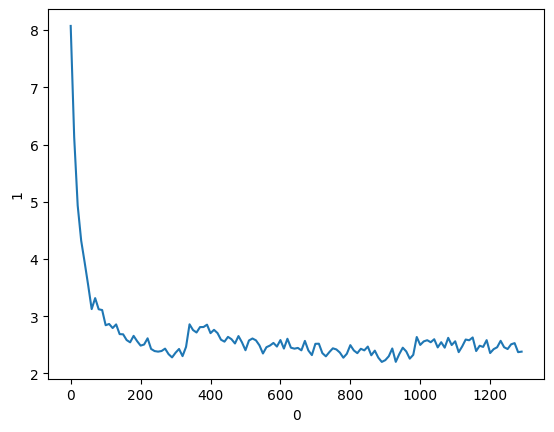

In [23]:
sns.lineplot(data=losses,x=0,y=1)

In [24]:
embedings = w2v.first_layer.weight.cpu().detach().numpy().T

In [25]:
from sklearn.preprocessing import MultiLabelBinarizer
import numpy as np

In [26]:
mlb = MultiLabelBinarizer(sparse_output=False,classes=word_set)

In [27]:
mlb.fit(np.array(word_set).reshape(-1,1))

,"classes classes: array-like of shape (n_classes,), default=NoneIndicates an ordering for the class labels.All entries should be unique (cannot contain duplicate classes).","OrderedSet(['...h', 'zipper'])"
,"sparse_output sparse_output: bool, default=FalseSet to True if output binary array is desired in CSR sparse format.",False


In [ ]:
def sliding_window_sampler(data,num_of_draws,window_size,encoder,mode='1:n'):
  left = window_size//2
  right = left + window_size%2

  words_idx = random.choices(list(range(len(data))),k=num_of_draws)

  X =[]
  y = []

  for i in words_idx:
    window = list(data[i-left:i+right])
    if len(window)!=window_size :
      continue
    window.pop(int(window_size/2))
    X.append(window)
    y.append(data[i])

  X = np.array(X)
  y = np.array(y).reshape(-1,1)

  X = encoder.transform(X)
  y = encoder.transform(y)

  match mode:
    case '1:n':
      return torch.tensor(y,dtype=torch.float),torch.tensor(X,dtype=torch.float)
    case 'n:1':
      return torch.tensor(X,dtype=torch.float),torch.tensor(y,dtype=torch.float)
    case _ :
      return None,None





In [29]:
sampler_1_n = DataSampler(dict(data=data_tuple,num_of_draws=64,encoder=mlb,mode='1:n',window_size=5),function=sliding_window_sampler)
w2v_1_n =meWord2Vec(len(word_set),len(word_set),6,int(len(word_set)*1.4),0.001).to(device)


In [30]:
losses = train(w2v_1_n,sampler_1_n,2000,torch.nn.BCEWithLogitsLoss)

loss is 0.7198365330696106
loss is 0.012184732593595982
loss is 0.012772854417562485
loss is 0.011290116235613823
loss is 0.010768688283860683
loss is 0.009644550271332264
loss is 0.009841086342930794
loss is 0.009509222581982613
loss is 0.00919776875525713
loss is 0.009133679792284966
loss is 0.009066584520041943
loss is 0.009041335433721542
loss is 0.008823766373097897
loss is 0.009195176884531975
loss is 0.00887201726436615
loss is 0.008733811788260937
loss is 0.009015140123665333
loss is 0.008775698952376842
loss is 0.008949135430157185
loss is 0.008729645051062107
loss is 0.009004592895507812
loss is 0.008456611074507236
loss is 0.008774640038609505
loss is 0.008691143244504929
loss is 0.00895751267671585
loss is 0.009348426014184952
loss is 0.00890413112938404
loss is 0.00872327946126461
loss is 0.00889582559466362
loss is 0.008664118126034737
loss is 0.008791754953563213
loss is 0.008710421621799469
loss is 0.008771289139986038
loss is 0.008822883479297161
loss is 0.008621829561

In [31]:
sampler_n_1 = DataSampler(dict(data=data_tuple,num_of_draws=64,encoder=mlb,mode='n:1',window_size=5),function=sliding_window_sampler)
w2v_n_1 =meWord2Vec(len(word_set),len(word_set),6,int(len(word_set)*1.4),0.001).to(device)

In [32]:
embedings_vanila = w2v.first_layer.weight.cpu().detach().numpy().T
embedings_1_n = w2v_1_n.first_layer.weight.cpu().detach().numpy().T
embedings_n_1 = w2v_n_1.first_layer.weight.cpu().detach().numpy().T

In [85]:
class EmbedingsContainer:
    def __init__(self,indicies,word_embeding_array):
        self.embedings = pd.DataFrame(word_embeding_array,index=indicies)
        embedings_lengths = np.linalg.norm(self.embedings,axis=1)
        self.embedings = self.embedings.div(embedings_lengths,axis=0)
    def __getitem__(self, key:str|int):
        if isinstance(key,int):
            return self.embedings.iloc[key].to_numpy()
        return self.embedings.loc[key].to_numpy()   
    def get_N_similar(self,target:str|np.ndarray,n:int,exclude: List=[]):
        
        if isinstance(target,str):
            target = self.embedings.loc[target]
        target_len = np.linalg.norm(target)



        vectors_len = np.linalg.norm(self.embedings,axis=1)

        scores = target@self.embedings.T
     
        
        scores:pd.DataFrame = scores / (vectors_len*target_len)
      
        scores_arg_sorted:pd.DataFrame = scores.sort_values(ascending=False).round(4)
  
        if len(exclude) !=0:
            scores_arg_sorted.drop(exclude,inplace=True)
        return scores_arg_sorted.iloc[:n]
    def add(self,terms:List|Tuple)->np.ndarray:

        target  = self.embedings.loc[terms]
        result = target.sum(axis=0)
        return (result/np.linalg.norm(result)).to_numpy()
    def normalize(self,vector):
        return (vector/np.linalg.norm(vector)).to_numpy()
        




In [86]:
ec_vanila = EmbedingsContainer(word_set,w2v.first_layer.weight.cpu().detach().numpy().T)
ec_1_n = EmbedingsContainer(word_set,w2v_1_n.first_layer.weight.cpu().detach().numpy().T)
ec_n_1= EmbedingsContainer(word_set,w2v_n_1.first_layer.weight.cpu().detach().numpy().T)

In [77]:
word_set

OrderedSet(['a', 'abandoned', 'about', 'above', 'abundance', 'accept', 'accepted', 'accepts', 'accident', 'accomplish', 'accurate', 'achieved', 'achievements', 'acoustics', 'across', 'act', 'acts', 'actually', 'add', 'added', 'address', 'adjusted', 'admire', 'admirers', 'admiring', 'admit', 'admitting', 'adult', 'adults', 'adventure', 'advice', 'advice:', 'afraid', 'after', 'afternoon', 'afternoons', 'afterward', 'afterward:', 'again', 'against', 'age', 'ago', 'agreement', 'ahead', 'air', 'alert', 'alive', 'all', 'allow', 'almonds', 'almost', 'alone', 'along', 'aloud', 'already', 'also', 'always', 'amber', 'ambitious', 'among', 'an', 'ancient', 'and', 'angels', 'angle', 'animals', 'ankles', 'announcer', 'another', 'anothers', 'answer', 'answered', 'answers', 'anticipation', 'any', 'anyone', 'anything', 'anywhere', 'apart', 'apartments', 'apologetic', 'apology', 'appear', 'appeared', 'appears', 'applause', 'apple', 'apples', 'appreciated', 'apprentices', 'approach', 'arch', 'arcs', 'are

In [90]:
ec_1_n.get_N_similar(ec_1_n.add(['blue','grain']),5,['blue','grain'])

burst        0.4807
gentle       0.4802
beat         0.4659
march        0.4622
cathedral    0.4497
dtype: float32

In [50]:
df_vanila = ec_vanila.get_N_similar(ec_vanila['you']+ec_vanila['young'],5,exclude=['you','young'])
df_1_n = ec_1_n.get_N_similar(ec_1_n['you']+ec_1_n['young'],5,exclude=['you','young'])
df_n_1 = ec_vanila.get_N_similar(ec_n_1['you']+ec_n_1['young'],5,exclude=['you','young'])

In [51]:
word_set

OrderedSet(['a', 'abandoned', 'about', 'above', 'abundance', 'accept', 'accepted', 'accepts', 'accident', 'accomplish', 'accurate', 'achieved', 'achievements', 'acoustics', 'across', 'act', 'acts', 'actually', 'add', 'added', 'address', 'adjusted', 'admire', 'admirers', 'admiring', 'admit', 'admitting', 'adult', 'adults', 'adventure', 'advice', 'advice:', 'afraid', 'after', 'afternoon', 'afternoons', 'afterward', 'afterward:', 'again', 'against', 'age', 'ago', 'agreement', 'ahead', 'air', 'alert', 'alive', 'all', 'allow', 'almonds', 'almost', 'alone', 'along', 'aloud', 'already', 'also', 'always', 'amber', 'ambitious', 'among', 'an', 'ancient', 'and', 'angels', 'angle', 'animals', 'ankles', 'announcer', 'another', 'anothers', 'answer', 'answered', 'answers', 'anticipation', 'any', 'anyone', 'anything', 'anywhere', 'apart', 'apartments', 'apologetic', 'apology', 'appear', 'appeared', 'appears', 'applause', 'apple', 'apples', 'appreciated', 'apprentices', 'approach', 'arch', 'arcs', 'are

In [52]:
df_vanila

potted      0.1697
lingered    0.1451
remember    0.1314
wavering    0.1268
sticky      0.1153
dtype: float32

In [53]:
df_1_n

clicks     0.5459
brown      0.5364
sunrise    0.5357
inks       0.5349
built      0.5235
dtype: float32

In [54]:
df_n_1

match      0.0512
added      0.0500
tires      0.0483
thud       0.0458
plastic    0.0458
dtype: float32

In [7]:
list(combinations(['AA','BB',"AA","CC"],2))

[('AA', 'BB'),
 ('AA', 'AA'),
 ('AA', 'CC'),
 ('BB', 'AA'),
 ('BB', 'CC'),
 ('AA', 'CC')]

In [ ]:
class GLoVE_embeding(nn.Module):
    def __init__(self,vocab_size,X_max,emebding_size,alpha=0.75):
        super().__init__()
        self.vocab_size = vocab_size
        self.embeding_size = emebding_size
        self.alpha = alpha 
        self.X_max = X_max
        ##
        self.target_embeding = nn.Embedding(vocab_size,emebding_size)
        self.context_embeding = nn.Embedding(vocab_size,emebding_size)
        #
        self.target_bias = nn.Embedding(vocab_size,1)
        self.context_bias = nn.Embedding(vocab_size,1)
        self.optimizer = None #torch.optim.AdamW(self.parameters(),lr=0.001)
        self.scheduler = None #lr_scheduler.CosineAnnealingWarmRestarts(self.optimizer)
    def forward(self,X,y):
        target_vectors = self.target_embeding(X[:,0])
        print(f' target vec {target_vectors.shape}')
        context_vectors = self.context_embeding(X[:,1])
        print(f'context vec {context_vectors.shape}')
        ##
        similarity:torch.Tensor = (context_vectors * target_vectors).sum(dim=-1)
        print(f'similarity vec {similarity.shape}')
        ##
        target_bias_vector = self.target_bias(X[:,0]).flatten()
        context_bias_vector = self.context_bias(X[:,1]).flatten()
        biases = target_bias_vector + context_bias_vector
        #
        print(f' biasese shape  = {biases.shape}')
        right_hand_side = similarity + biases + torch.log(y)
        
        
        return torch.clamp((y/self.X_max)**(self.alpha),max=1)*right_hand_side

        
    @staticmethod
    def make_vocab_dict(word_iterable: List[str],window_size:int)-> Dict[tuple,int]:
        
        result = {}
        vocab_size = len(word_iterable)
        for i in range(vocab_size-window_size+1):
            window = word_iterable[i:i+window_size]
            pairs = tuple(combinations(window,2))
            for pair in pairs:
                if pair not in result.keys():
                    result[pair]=0
                result[pair]+=1
        return result

    def _train(self,dataloader:torch.utils.data.DataLoader,learning_rate=0.001,num_of_epochs=200,device='cpu'):
        loss_score = []
        loss_func = torch.nn.MSELoss()
        if self.optimizer is None:
            self.optimizer = torch.optim.AdamW(self.parameters(),lr=learning_rate)
        if self.scheduler is None: 
            self.scheduler = lr_scheduler.CosineAnnealingWarmRestarts(self.optimizer,T_0=num_of_epochs//3,T_mult=2,eta_min=0.000015)
        for _ in range(num_of_epochs):
            for batch_X,batch_y in dataloader:
                
                self.optimizer.zero_grad()

                batch_X = batch_X.to(device)
                batch_y = batch_y.to(device)

                preds = self.forward(batch_X,batch_y)
                l = loss_func(preds,batch_y).to(device=device,dtype=batch_y.dtype)

                l.backward()
                self.optimizer.step()
                self.scheduler.step()

                loss_score.append(l.item())
        return loss_score

    

In [111]:
class Glove_dataset(torch.utils.data.Dataset):
    def __init__(self,data_dict: Dict[Tuple,int],word_set:ordered_set.OrderedSet):
        super().__init__()

        self.data_set = [[word_set.index(row[0]),word_set.index(row[1]),c] for row,c in data_dict.items()]
        self.word_set = word_set        
    def __getitem__(self, index):
        return torch.tensor(self.data_set[index][:2]), torch.tensor(self.data_set[index][2])
    def __len__(self):
        return len(self.data_set)
    

In [112]:
glove = GLoVE_embeding(vocab_size=len(word_set),emebding_size=int(len(word_set)*1.3),X_max=1000).to(device=device)

In [113]:
me_dataset = Glove_dataset(glove.make_vocab_dict(word_iterable=data_tuple,window_size=5),word_set=word_set)

In [114]:
glove_dataloader = torch.utils.data.DataLoader(me_dataset,int(len(me_dataset)//20),shuffle=True)

In [115]:
glove._train(glove_dataloader,device=device)

 target vec torch.Size([1532, 3632])
context vec torch.Size([1532, 3632])
similarity vec torch.Size([1532])
 biasese shape  = torch.Size([1532])


RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn